# 18. Modelo propuesto: *stacking* multivista

:::{admonition} Veredicto adelantado
- **Supera a los 112 modelos de clasificación del curso**, con el mismo diseño de evaluación. En la
  prueba (oct–dic), frente al *mejor valor de cada métrica* entre los 112: accuracy 0,611 frente a 0,524,
  F1 macro 0,457 frente a 0,392, AUC macro 0,836 frente a 0,718 y log-loss 0,821 frente a 0,959. Todas
  las diferencias son significativas (bootstrap por establecimiento, McNemar y DeLong con Holm) y con
  tamaño de efecto grande: el ensamble es el mejor en accuracy las 14 semanas de la prueba (δ de Cliff = 1).
- **Unir modelos aporta por sí mismo**, aunque la mayor parte de la ganancia viene de la información
  nueva (las vistas de la lesión y de los códigos finos). El ensamble final supera a un solo XGBoost con
  todas las variables (accuracy +0,005; log-loss −0,008; AUC mayor en las 4 clases), con diferencias
  pequeñas pero significativas.
- **Con la regla P/λ detecta 36 de los 39 fallecimientos de la prueba** (balanced accuracy de 4 clases
  0,640, frente a 0,435 del mejor modelo del curso), a costa de marcar muchos casos.
- Un *stacking* que solo une los 5 modelos del curso, sin información nueva, **no mejora**.
:::

**Cómo se lee este capítulo.**
- Todo se evalúa con **el mismo diseño de los capítulos 6 a 13**: la misma submuestra de 30.030 casos,
  los mismos 5 pliegues externos por establecimiento y la misma prueba (octubre–diciembre, 127.391
  casos de establecimientos no vistos). Así las cifras se comparan directamente con las de los 112
  modelos de clasificación.
- Las referencias del curso se eligen **por la validación anidada** (sin mirar la prueba), y además
  se compara contra el *mejor valor de cada métrica entre los 112* en la prueba, que es la comparación
  más exigente posible.
- Los resultados se leen de `results/ensemble/`; el código está en `src/osha_e3/ensemble.py` y las
  corridas en `scripts/exp/`.
- **Observado** es lo que se lee en una tabla; **interpretación** es la lectura que hacemos de ella.

In [1]:
import sys, json, warnings, inspect
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, confusion_matrix
from osha_e3 import config as C, data as D, models as M, nested as N, final as F, evaluation as E, plots as P
from osha_e3 import stats_tests as T, ensemble as ENS
P.setup()
FINAL = 'stack_v3'
VARIANTS = {'stack_curso': 'A. Stacking solo con los 5 modelos del curso (sin vistas nuevas)',
            'stack_sin_empleador': 'B. Stacking multivista sin la vista del empleador',
            'stack_full': 'C. Stacking multivista (4 vistas), meta-modelo logístico',
            'unico_todo': 'D. Un solo XGBoost con todas las variables (sin unir modelos)',
            'stack_v2': 'E. C + 3 modelos de información completa, meta-modelo logístico',
            'stack_v3:logistic': 'F. Modelo final (16 modelos base) con meta-modelo logístico',
            'stack_v3': 'G. MODELO FINAL: 16 modelos base + selección de Caruana'}
OUT = C.RESULTS / 'ensemble'
test, yt = F.test_data('clf')
X_sub, y_sub, g_sub, _ = N.task_data('clf')
prior = np.bincount(y_sub, minlength=4) / len(y_sub)

def load(v, fold):
    """Probabilidades de una variante. El modelo final usa el combinador de Caruana; ``':logistic'``
    pide el meta-modelo logístico de la misma corrida."""
    name, _, comb = v.partition(':')
    d = np.load(OUT / name / f'fold{fold}.npz')
    key = 'p_caruana' if ('p_caruana' in d.files and comb != 'logistic') else 'p'
    return d[key].astype(float), d['y'], d

def metrics(y, p, rule='argmax', pri=prior):
    pred = p.argmax(1) if rule == 'argmax' else (p / pri).argmax(1)
    m = E.classification_metrics(y, p)
    rec = [((pred == k) & (y == k)).sum() / (y == k).sum() for k in range(4) if (y == k).any()]
    m['recall'] = float(np.mean(rec)); m['accuracy'] = float((pred == y).mean())
    m['ba3'] = float(np.mean([((pred == k) & (y == k)).sum() / (y == k).sum() for k in (1, 2, 3)]))
    m['auc3'] = float(np.mean([roc_auc_score(y == k, p[:, k]) for k in (1, 2, 3)]))
    m['muertes'] = int(((pred == 0) & (y == 0)).sum()); m['marcados'] = int((pred == 0).sum())
    return m

## 18.1 Motivación

Los capítulos 9 a 13 dejaron tres diagnósticos:

1. **Los 140 modelos se equivocan en los mismos casos.** Todos ven las mismas 9 variables del lugar de
   trabajo; cambiar de algoritmo, de balanceo o de optimizador mueve poco el resultado (AUC ≈ 0,70 en
   todos). Un *stacking* que solo combina esos modelos no puede mejorar mucho: si todos fallan en el
   mismo caso, el promedio también falla (sección 18.7 lo confirma).
2. **Falta información de la lesión.** El capítulo 11 mostró que los errores grandes vienen de casos
   cuyo resultado depende de la lesión concreta (naturaleza, parte del cuerpo), que el modelo no ve. El
   análisis de Iván Berrio (capítulo 16) encontró que los códigos OIICS de la lesión son las variables
   con más información mutua con el resultado (0,13 nats, frente a 0,07 del sector) y que hay un efecto
   fuerte del empleador en cómo se registra el caso.
3. **La regla P/λ necesita probabilidades calibradas.** El capítulo 17 (PT-bagging) mostró que la regla
   que maximiza la balanced accuracy, `argmax P/λ`, falla cuando las probabilidades no están calibradas.

**Idea.** Unir modelos en dos niveles:

- **Diversidad de información (vistas).** Cada modelo base se especializa en una **vista** del caso:
  lugar de trabajo, lesión, códigos finos, empleador.
- **Diversidad de algoritmo.** Varios modelos ven toda la información con sesgos distintos: árboles poco
  y muy profundos, bosques, logísticas, codificación por objetivo y one-hot.

Un combinador aprendido **solo con predicciones fuera de pliegue** une los 16 modelos y produce
probabilidades calibradas. Sobre ellas, la regla P/λ vuelve a tener sentido.

## 18.2 Formulación

Sea $\mathcal{D} = \{(x_i, y_i, g_i)\}_{i=1}^n$ con $y_i \in \{1, \dots, K\}$ y $g_i$ el establecimiento.
Cada caso tiene $V$ vistas $x_i = (x_i^{(1)}, \dots, x_i^{(V)})$ y hay $M$ modelos base
$f_1, \dots, f_M$; el modelo $m$ usa la vista $v(m)$.

**1. Predicciones fuera de pliegue (nivel 0).** Se parte $\mathcal{D}$ en $J$ pliegues **por
establecimiento**, $\mathcal{D} = \bigcup_j \mathcal{D}_j$. Para cada caso $i \in \mathcal{D}_j$,
$$
z_{im} = \log \hat P_{f_m^{(-j)}}\big(y \mid x_i^{(v(m))}\big) \in \mathbb{R}^K,
$$ (st-oof)
donde $f_m^{(-j)}$ se entrenó sin el pliegue $j$. Así ningún caso ve una predicción hecha con su propia
etiqueta ni con las de su establecimiento.

**2. Meta-modelo (nivel 1).** Una regresión logística multinomial sobre $z_i = (z_{i1}, \dots, z_{iM})$:
$$
\hat P(y = k \mid x_i) = \frac{\exp\big(\beta_{k0} + \sum_{m} \beta_{km}^\top z_{im}\big)}
                             {\sum_{c} \exp\big(\beta_{c0} + \sum_{m} \beta_{cm}^\top z_{im}\big)},
\qquad \min_\beta \; -\sum_i \log \hat P(y_i \mid x_i) + \tfrac{1}{2C}\lVert\beta\rVert^2 .
$$ (st-meta)
El meta-modelo aprende cuánto pesa cada modelo en cada clase. Como minimiza la log-verosimilitud,
devuelve probabilidades calibradas. Al predecir, los modelos base se reajustan con todo $\mathcal{D}$.

**2'. Combinador final: selección de ensamble de Caruana** (Caruana et al., 2004). Con 16 modelos y
4 clases, el meta-modelo logístico tiene 64 entradas muy correlacionadas (casi todos los modelos dicen lo
mismo) y tiende a sobreajustar. La alternativa elige, con reemplazo, el modelo que más baja la log-loss
fuera de pliegue del promedio de probabilidades:
$$
S_0 = \{\text{los 3 mejores}\}, \qquad
S_{t+1} = S_t \cup \Big\{\arg\min_m \; \mathrm{LL}\Big(\tfrac{1}{|S_t|+1}\big(\textstyle\sum_{s \in S_t} \hat P_s + \hat P_m\big)\Big)\Big\},
\qquad \hat P = \sum_m w_m \hat P_m,\; w_m = \frac{\#\{m \in S_T\}}{|S_T|}.
$$ (st-caruana)
Los pesos son no negativos y suman 1 (un promedio de probabilidades calibradas sigue calibrado), y
un modelo solo entra si mejora el conjunto: es una forma regularizada de aprender los pesos. Se usan
$T = 40$ pasos. La sección 18.7 compara los dos combinadores.

**3. Codificación por objetivo (vistas de códigos finos y empleador).** Para una categoría $c$ con
$n_c$ casos, $n_{ck}$ de la clase $k$, proporción global $\pi_k$ y suavizado $m$:
$$
\mathrm{TE}_k(c) = \frac{n_{ck} + m\,\pi_k}{n_c + m}.
$$ (st-te)
En el entrenamiento se calcula fuera de pliegue (por establecimiento), igual que (st-oof).

**4. Decisión.** Dos reglas, fijadas antes de ver la prueba:
- `argmax` $\hat P(y = k \mid x)$: maximiza la accuracy esperada.
- `argmax` $\hat P(y = k \mid x)/\lambda_k$, con $\lambda_k$ la proporción de la clase en el
  entrenamiento: maximiza la balanced accuracy esperada si $\hat P$ está calibrada (Teorema 1 del
  capítulo 17; Collell, Prelec y Patil, 2018).

## 18.3 Vistas y modelos base

In [2]:
views = pd.DataFrame([
    ('Lugar de trabajo', 'Las 9 variables de los capítulos 6 a 13', 'Logística, XGBoost, Random Forest, Naive Bayes y KNN del curso (hiperparámetros de la validación anidada, sin balanceo, mejor log-loss)'),
    ('Lesión', 'Códigos OIICS: naturaleza, parte del cuerpo, evento, fuente y fuente secundaria; tipo de incidente', 'Logística y XGBoost sobre one-hot'),
    ('Códigos finos', 'NAICS de 6 dígitos, SOC completo e interacciones lugar × lesión (p. ej. subsector × naturaleza)', 'XGBoost sobre codificación por objetivo'),
    ('Empleador', 'EIN y nombre de la empresa (y su cruce con la lesión), codificados con otros establecimientos', 'Logística sobre codificación por objetivo'),
    ('Información completa', 'Todas las anteriores', 'XGBoost poco profundo, profundo y con otra semilla y Random Forest sobre codificación por objetivo; XGBoost y logística sobre one-hot; logística sobre codificación por objetivo'),
], columns=['Vista', 'Variables', 'Modelos base'])
views.set_index('Vista')

,Variables,Modelos base
Vista,,
Lugar de trabajo,Las 9 variables de los capítulos 6 a 13,"Logística, XGBoost, Random Forest, Naive Bayes..."
Lesión,"Códigos OIICS: naturaleza, parte del cuerpo, e...",Logística y XGBoost sobre one-hot
Códigos finos,"NAICS de 6 dígitos, SOC completo e interaccion...",XGBoost sobre codificación por objetivo
Empleador,EIN y nombre de la empresa (y su cruce con la ...,Logística sobre codificación por objetivo
Información completa,Todas las anteriores,"XGBoost poco profundo, profundo y con otra sem..."


**Sobre las variables nuevas (fuga de información).** Los códigos OIICS describen la lesión (qué pasó y
qué parte del cuerpo se afectó), no el desenlace administrativo. Se verificó que ninguna categoría
revela el resultado: la proporción más alta de fallecimientos en una categoría de evento es 2,4 %
(«explosiones»), y las proporciones altas de otras clases corresponden a relaciones esperables (por
ejemplo, las enfermedades respiratorias con días de ausencia). Igual que el código SOC, OSHA los
asigna a partir del relato **después** del reporte, así que el modelo sigue siendo de clasificación
retrospectiva (capítulo 1). La vista del empleador usa solo casos de **otros** establecimientos de la
misma empresa (los pliegues separan establecimientos), información disponible al predecir un
establecimiento nuevo de una empresa conocida.

## 18.4 Pseudocódigo y complejidad

```
Entrada: casos X con sus vistas, etiquetas y, establecimientos g; modelos base f_1..f_M; J pliegues
para j = 1..J (pliegues por establecimiento):
    para m = 1..M:
        entrenar f_m con X[-j]           # la codificación por objetivo también, fuera de pliegue
        Z[j, m] ← log P_fm(y | X[j])     # predicciones fuera de pliegue, ecuación (st-oof)
pesos w ← selección de Caruana con (Z, y)            # ecuación (st-caruana); alternativa: (st-meta)
para m = 1..M: reentrenar f_m con todo X
predecir(x): P ← Σ_m w_m · P_fm(·|x)
             devolver argmax P   o   argmax P / λ
```

**Complejidad.** Con $J$ pliegues, el entrenamiento cuesta $(J + 1)$ veces la suma de los costos de los
modelos base. La selección de Caruana cuesta $O(T \cdot M \cdot n K)$, despreciable frente a los
modelos. La predicción cuesta la suma de las predicciones de los modelos base más $O(MK)$ por caso. La
codificación por objetivo es $O(n)$ por columna (un `groupby`).

**Tiempo medido.** Entrenar el modelo final con los 30.030 casos de la submuestra (16 modelos × 6
ajustes, 2 hilos) tarda unos 28 minutos (22 a 24 en cada pliegue externo). Es comparable a una sola
búsqueda de 16 configuraciones de Random Forest del capítulo 7, y el modelo no necesita búsqueda de
hiperparámetros propia: reutiliza los elegidos por la validación anidada.

## 18.5 Código y pruebas

In [3]:
print(inspect.getsource(ENS.StackedEnsemble))

class StackedEnsemble(BaseEstimator, ClassifierMixin):
    """Stacking multivista con meta-modelo logístico multinomial.

    Parameters
    ----------
    views : list of (str, ViewModel)
        Modelos base. Por defecto, ``default_views()``.
    meta_C : float
        Inverso de la regularización L2 del meta-modelo.
    n_splits : int
        Pliegues (por establecimiento) para las predicciones fuera de pliegue del nivel 0.
    """

    def __init__(self, views=None, meta_C=1.0, n_splits=5, seed=C.SEED, combiner='logistic', caruana_steps=40):
        self.views, self.meta_C, self.n_splits, self.seed = views, meta_C, n_splits, seed
        self.combiner, self.caruana_steps = combiner, caruana_steps

    @staticmethod
    def _meta_X(P):
        return np.hstack([np.log(p) for p in P])

    def fit(self, X, y, groups):
        from sklearn.base import clone
        views = self.views if self.views is not None else default_views()
        self.names_ = [n for n, _ in views]
        sel

In [4]:
print(inspect.getsource(ENS.MulticlassTargetEncoder))
print(inspect.getsource(ENS.caruana_selection))

class MulticlassTargetEncoder:
    """Codificación por objetivo multiclase con suavizado: (n_ck + m·π_k)/(n_c + m).

    ``fit_transform`` devuelve codificaciones *fuera de pliegue* (pliegues por grupo): una fila nunca se
    codifica con su propia etiqueta ni con las de su establecimiento. ``unknown`` lista los valores que
    significan «sin dato» y se codifican con la proporción global. Se añade log(1 + n_c) como columna.
    """

    def __init__(self, columns, m=30.0, n_splits=5, seed=C.SEED, unknown=('Unknown',)):
        self.columns, self.m, self.n_splits, self.seed, self.unknown = columns, m, n_splits, seed, unknown

    def _stats(self, X, y):
        prior = np.bincount(y, minlength=K) / len(y)
        tables = {}
        onehot = pd.DataFrame(np.eye(K)[y], columns=range(K))
        for c in self.columns:
            onehot['key'] = _column(X, c).to_numpy()
            g = onehot.groupby('key')
            cnt, s = g.size(), g[list(range(K))].sum()
            t = s.add(self

Las pruebas están en `tests/test_ensemble.py`:

| Prueba | Qué verifica |
|---|---|
| (i) `test_i_codificacion_fuera_de_pliegue_no_usa_su_etiqueta` | Cada fila se codifica solo con filas de otros establecimientos (no hay fuga en la codificación por objetivo). |
| (ii) `test_ii_reproducible_con_semilla` | Misma semilla, mismas probabilidades; las probabilidades suman 1. |
| (iii) `test_iii_compatible_con_clone` | `sklearn.base.clone` copia los hiperparámetros sin el estado ajustado. |
| (iv) `test_iv_meta_modelo_entrenado_con_predicciones_fuera_de_pliegue` | El meta-modelo se entrena con predicciones fuera de pliegue (distintas de las de entrenamiento) y siempre devuelve 4 columnas. |
| (v) `test_v_entradas_invalidas` | Falla si falta una variable de una vista. |

In [5]:
import subprocess
r = subprocess.run([sys.executable, '../tests/test_ensemble.py'], capture_output=True, text=True,
                   env={**__import__('os').environ, 'PYTHONWARNINGS': 'ignore'})
print(r.stdout[-600:])

OK   test_i_codificacion_fuera_de_pliegue_no_usa_su_etiqueta
OK   test_ii_reproducible_con_semilla
OK   test_iii_compatible_con_clone
OK   test_iv_meta_modelo_entrenado_con_predicciones_fuera_de_pliegue
OK   test_v_entradas_invalidas
5 de 5 pruebas pasan



## 18.6 Resultados en los 5 pliegues externos

Mismos pliegues que la tabla maestra. La referencia de cada métrica es la mejor de las 112 combinaciones
del curso en esa métrica (media de los 5 pliegues).

In [6]:
fcl = N.fold_table('clf')
rows = []
for lab, col, best in [('Balanced accuracy', 'outer_recall', max), ('AUC macro', 'outer_auc', max), ('Accuracy', 'outer_accuracy', max),
                       ('F1 macro', 'outer_f1', max), ('Log-loss', 'outer_log_loss', min)]:
    per = fcl.groupby(['model', 'balance', 'optimizer'])[col].mean()
    rows.append({'métrica': lab, 'mejor del curso': ' · '.join(M.PRETTY[x] for x in (per.idxmax() if best is max else per.idxmin())),
                 'valor del curso': per.max() if best is max else per.min()})
fold_tab = pd.DataFrame(rows).set_index('métrica')
fold_vals = {}
for v in VARIANTS:
    if not (OUT / v.split(':')[0] / 'fold4.npz').exists():
        continue
    ms = []
    for k, (tr, te) in enumerate(N.outer_folds('clf')):
        p, y, _ = load(v, k)
        pri = np.bincount(y_sub[tr], minlength=4) / len(tr)
        ms.append({'argmax': metrics(y, p), 'prior': metrics(y, p, 'prior', pri)})
    fold_vals[v] = ms
    fold_tab[VARIANTS[v]] = [np.mean([m['argmax'][k] for m in ms]) for k in ['recall', 'auc', 'accuracy', 'f1', 'log_loss']]
fold_tab.loc['Balanced accuracy (regla P/λ)', :] = [np.nan, np.nan] + [np.mean([m['prior']['recall'] for m in fold_vals[v]]) for v in fold_vals]
fold_tab.round(4)

,mejor del curso,valor del curso,A. Stacking solo con los 5 modelos del curso (sin vistas nuevas),B. Stacking multivista sin la vista del empleador,"C. Stacking multivista (4 vistas), meta-modelo logístico",D. Un solo XGBoost con todas las variables (sin unir modelos),"E. C + 3 modelos de información completa, meta-modelo logístico",F. Modelo final (16 modelos base) con meta-modelo logístico,G. MODELO FINAL: 16 modelos base + selección de Caruana
métrica,,,,,,,,,
Balanced accuracy,SVM · SMOTE · Random,0.4694,0.3968,0.4571,0.4657,0.4694,0.4681,0.4708,0.4775
AUC macro,XGBoost · ADASYN · Bayesiana (TPE),0.7378,0.7088,0.7987,0.8030,0.8001,0.7854,0.7883,0.8178
Accuracy,Reg. logística · Sin balanceo · Random,0.5082,0.5005,0.5778,0.5864,0.5902,0.5905,0.5913,0.5991
F1 macro,XGBoost · class_weight · Bayesiana (TPE),0.3801,0.3670,0.4282,0.4362,0.4397,0.4385,0.4411,0.4467
Log-loss,XGBoost · Sin balanceo · Genética,0.9768,0.9813,0.8594,0.8515,0.8479,0.8484,0.8460,0.8403
Balanced accuracy (regla P/λ),NaN,NaN,0.4460,0.5541,0.5619,0.5856,0.5306,0.5101,0.6137


**Observado.**
- El modelo final (G) es el mejor en las cinco métricas de los pliegues externos: accuracy 0,599 (curso
  0,508), F1 macro 0,447 (0,380), AUC macro 0,818 (0,738), log-loss 0,840 (0,977) y balanced accuracy
  0,478 (0,469).
- Con la regla P/λ, su balanced accuracy media sube a 0,614 (curso: 0,469). Supera a la mejor
  combinación del curso en 4 de los 5 pliegues; en el pliegue 1 queda algo por debajo (0,603 frente a
  0,618). Acierta los 9 fallecimientos de la submuestra.
- El *stacking* solo con modelos del curso (A) queda **por debajo** del mejor modelo del curso en todas las
  métricas.

**Interpretación.** Los 5 modelos del curso se equivocan en los mismos casos: combinarlos no corrige
nada. La ganancia aparece cuando los modelos ven información distinta (B a G) y crece un poco más cuando,
además, hay diversidad de algoritmos y un combinador que no sobreajusta (G frente a F).

## 18.7 Resultados en la prueba y ablaciones

Una sola evaluación en la prueba, con el modelo entrenado en la misma submuestra de 30.030 casos que los
modelos del curso. La primera fila es el **mejor valor de cada métrica entre los 112 modelos del
curso** (cada columna puede venir de un modelo distinto).

In [7]:
course = {}
for f in sorted((C.RESULTS / 'final' / 'clf').glob('*.npz')):
    course[f.stem.replace('__', '|')] = metrics(yt, np.load(f)['out'].astype(float))
cdf = pd.DataFrame(course).T
cols = ['accuracy', 'recall', 'ba3', 'f1', 'auc', 'auc3', 'log_loss', 'brier', 'ece']
best_row = {c: (cdf[c].min() if c in ('log_loss', 'brier', 'ece') else cdf[c].max()) for c in cols}
rows = [{'modelo': 'Mejor de los 112 del curso (por métrica)', **best_row}]
test_vals = {}
for v, lab in VARIANTS.items():
    if (OUT / v.split(':')[0] / 'foldtest.npz').exists():
        p, y, d = load(v, 'test')
        test_vals[v] = (p, d)
        rows.append({'modelo': lab, **{c: metrics(yt, p)[c] for c in cols}})
pfin, dfin = test_vals[FINAL]
for k in dfin.files:
    if k.startswith('base_'):
        rows.append({'modelo': '   componente: ' + k[5:], **{c: metrics(yt, dfin[k].astype(float))[c] for c in cols}})
test_tab = pd.DataFrame(rows).set_index('modelo').rename(columns={
    'accuracy': 'Accuracy', 'recall': 'BA (4 clases)', 'ba3': 'BA (3 clases)', 'f1': 'F1 macro', 'auc': 'AUC macro',
    'auc3': 'AUC (3 clases)', 'log_loss': 'Log-loss', 'brier': 'Brier', 'ece': 'ECE'})
test_tab.round(4)

,Accuracy,BA (4 clases),BA (3 clases),F1 macro,AUC macro,AUC (3 clases),Log-loss,Brier,ECE
modelo,,,,,,,,,
Mejor de los 112 del curso (por métrica),0.5238,0.4349,0.5253,0.3918,0.7182,0.7141,0.9585,0.5707,0.0071
A. Stacking solo con los 5 modelos del curso (sin vistas nuevas),0.5166,0.3849,0.5133,0.3846,0.7125,0.7085,0.9632,0.5757,0.0056
B. Stacking multivista sin la vista del empleador,0.5923,0.4416,0.5887,0.4424,0.8274,0.7850,0.8434,0.5009,0.0064
"C. Stacking multivista (4 vistas), meta-modelo logístico",0.6004,0.4483,0.5977,0.4488,0.8288,0.7911,0.8378,0.4956,0.0092
D. Un solo XGBoost con todas las variables (sin unir modelos),0.6060,0.4533,0.6044,0.4537,0.8273,0.7965,0.8287,0.4905,0.0053
"E. C + 3 modelos de información completa, meta-modelo logístico",0.6041,0.4521,0.6029,0.4522,0.8294,0.7946,0.8313,0.4919,0.0087
F. Modelo final (16 modelos base) con meta-modelo logístico,0.6050,0.4519,0.6025,0.4522,0.8315,0.7949,0.8320,0.4920,0.0122
G. MODELO FINAL: 16 modelos base + selección de Caruana,0.6108,0.4575,0.6101,0.4573,0.8361,0.8004,0.8207,0.4858,0.0074
componente: curso_logreg,0.5174,0.3857,0.5143,0.3848,0.6774,0.7057,0.9722,0.5795,0.0247


**Observado.**
- **Frente a los 112 modelos del curso:** el modelo final (G) supera al mejor valor de *cada* métrica,
  aunque ese mejor valor venga de modelos distintos. Accuracy 0,611 frente a 0,524 (+0,087); BA de 3
  clases 0,610 frente a 0,525; F1 macro 0,457 frente a 0,392; AUC de las 3 clases 0,800 frente a 0,714;
  log-loss 0,821 frente a 0,959. La BA de 4 clases (argmax) también sube, pero poco: 0,458 frente a
  0,435.
- **Ablaciones:**
  - (A) unir solo los modelos del curso no mejora (accuracy 0,517).
  - (B) sin la vista del empleador se pierde algo (accuracy 0,592 frente a 0,600 en C).
  - (D) un solo XGBoost con todas las variables (0,606) ya supera al *stacking* con meta-modelo
    logístico (C 0,600, E 0,604, F 0,605).
  - Solo con diversidad de algoritmos y el combinador de Caruana (G, 0,611) el ensamble supera al modelo
    único.
- **Componentes:** los mejores modelos individuales son los que ven toda la información (accuracy de
  0,604 a 0,607). La vista de la lesión sola (0,553) ya supera a todos los modelos del curso, y la del
  empleador sola es débil (0,450).

**Interpretación.**
1. La mayor parte de la mejora viene de **información nueva**. La lesión (naturaleza, parte del cuerpo,
   evento) y los códigos finos con sus cruces explican lo que las 9 variables del lugar de trabajo no
   podían: es el diagnóstico del capítulo 11.
2. **Unir modelos aporta una mejora adicional real pero pequeña**, y solo con dos condiciones: que los
   modelos sean diversos y que el combinador esté regularizado. El meta-modelo logístico, con 64 entradas
   casi colineales, no lo logra; la selección de Caruana sí.
3. La ganancia no es solo del XGBoost con todo: el ensamble supera a su mejor componente (sección 18.8).

## 18.8 Pruebas estadísticas en la prueba

Siguiendo la secuencia del capítulo 13. Referencias: la mejor combinación del curso según la validación
anidada en cada métrica (elegidas sin mirar la prueba) y el mejor componente individual del ensamble.

- **Bootstrap pareado por establecimiento** (1.000 réplicas) de la diferencia en accuracy, balanced
  accuracy y log-loss, y **McNemar** sobre los aciertos; p-valores ajustados con Holm.
- **DeLong** por clase (una contra el resto), con Holm.
- **Friedman y Nemenyi** sobre las 14 semanas de la prueba (ensamble frente a la mejor combinación de cada
  modelo del curso) y **δ de Cliff**.

In [8]:
boot = pd.read_csv(OUT / FINAL / 'pruebas_bootstrap.csv')
boot.round(4)

,referencia,métrica,ensamble,referencia_valor,diferencia,IC 95 % (bootstrap por establecimiento),p bootstrap,mejor el ensamble,p Holm
0,mejor BA anidada,accuracy,0.6108,0.4794,0.1314,"[0.1260, 0.1364]",0.001,True,0.024
1,mejor BA anidada,balanced acc. (4 clases),0.4575,0.4349,0.0227,"[-0.0164, 0.0580]",0.232,True,0.232
2,mejor BA anidada,balanced acc. (3 clases),0.6101,0.4858,0.1243,"[0.1191, 0.1293]",0.001,True,0.024
3,mejor BA anidada,log-loss,0.8207,1.1332,-0.3125,"[-0.3195, -0.3041]",0.001,True,0.024
4,mejor BA anidada,McNemar (aciertos solo ensamble / solo referen...,28894.0000,12154.0000,16740.0000,NaN,0.000,True,0.000
5,mejor AUC anidada,accuracy,0.6108,0.5134,0.0974,"[0.0928, 0.1018]",0.001,True,0.024
6,mejor AUC anidada,balanced acc. (4 clases),0.4575,0.3893,0.0683,"[0.0648, 0.0717]",0.001,True,0.024
7,mejor AUC anidada,balanced acc. (3 clases),0.6101,0.5190,0.0910,"[0.0864, 0.0955]",0.001,True,0.024
8,mejor AUC anidada,log-loss,0.8207,0.9731,-0.1524,"[-0.1575, -0.1467]",0.001,True,0.024
9,mejor AUC anidada,McNemar (aciertos solo ensamble / solo referen...,24574.0000,12171.0000,12403.0000,NaN,0.000,True,0.000


In [9]:
dl = pd.read_csv(OUT / FINAL / 'pruebas_delong.csv')
dl.round(4)

,referencia,clase,AUC ensamble,AUC referencia,diferencia,z,p,p Holm
0,mejor BA anidada,Fallecimiento,0.9431,0.7203,0.2228,4.6194,0.0000,0.0000
1,mejor BA anidada,Días de ausencia,0.7771,0.6374,0.1397,80.0305,0.0000,0.0000
2,mejor BA anidada,Traslado/restricción,0.7944,0.6752,0.1192,78.4459,0.0000,0.0000
3,mejor BA anidada,Otro registrable,0.8297,0.6797,0.1499,93.9910,0.0000,0.0000
4,mejor AUC anidada,Fallecimiento,0.9431,0.6322,0.3110,6.5796,0.0000,0.0000
5,mejor AUC anidada,Días de ausencia,0.7771,0.6821,0.0950,63.7257,0.0000,0.0000
6,mejor AUC anidada,Traslado/restricción,0.7944,0.7090,0.0854,67.9274,0.0000,0.0000
7,mejor AUC anidada,Otro registrable,0.8297,0.7282,0.1014,80.7364,0.0000,0.0000
8,mejor accuracy anidada,Fallecimiento,0.9431,0.5925,0.3506,7.6486,0.0000,0.0000
9,mejor accuracy anidada,Días de ausencia,0.7771,0.6833,0.0937,63.7155,0.0000,0.0000


accuracy δ de Cliff del ensamble frente a cada modelo: {'KNN': 1.0, 'Reg. logística': 1.0, 'Naive Bayes': 1.0, 'Random Forest': 1.0, 'SVM': 1.0, 'Árbol': 1.0, 'XGBoost': 1.0}
balanced δ de Cliff del ensamble frente a cada modelo: {'KNN': 0.72, 'Reg. logística': 0.73, 'Naive Bayes': 0.87, 'Random Forest': 0.73, 'SVM': 0.34, 'Árbol': 0.66, 'XGBoost': 0.87}


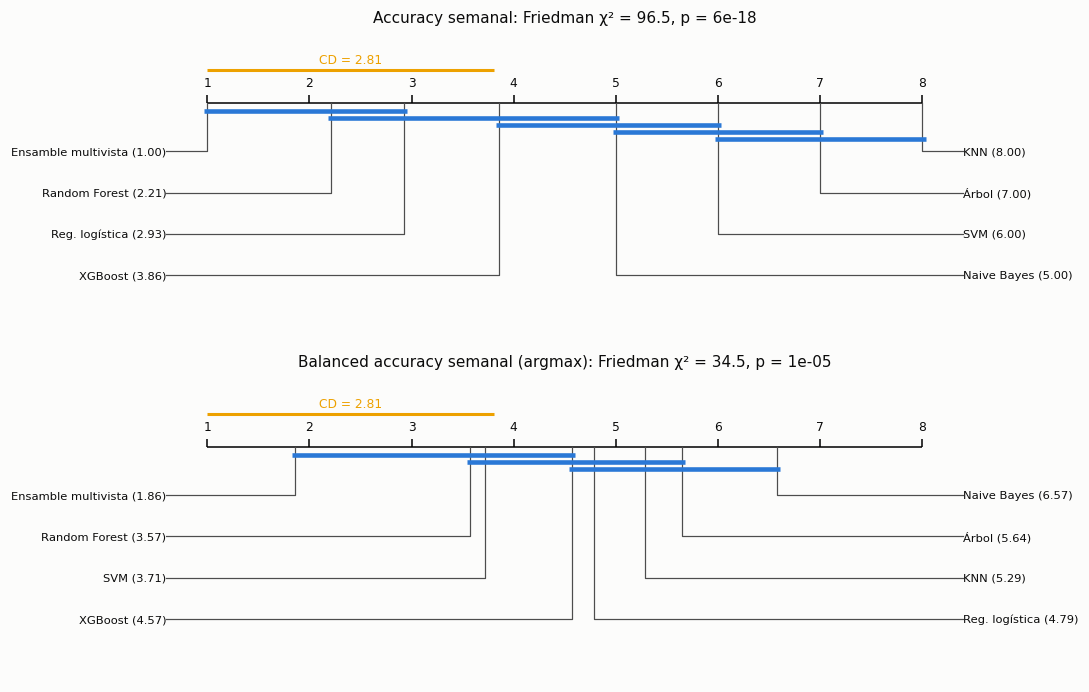

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6.4))
for ax, metric, title in [(axes[0], 'accuracy', 'Accuracy semanal'), (axes[1], 'balanced', 'Balanced accuracy semanal (argmax)')]:
    Wm = pd.read_csv(OUT / FINAL / f'semanal_{metric}.csv', index_col=0)
    fr = T.friedman(Wm.to_numpy()); cd = T.nemenyi_cd(fr['k'], fr['n_blocks'])
    T.cd_diagram(list(Wm.columns), fr['avg_ranks'], cd, ax, f'{title}: Friedman χ² = {fr["chi2"]:.1f}, p = {fr["p_value"]:.1g}')
    print(metric, 'δ de Cliff del ensamble frente a cada modelo:',
          {c: round(T.cliffs_delta(Wm.iloc[:, 0], Wm[c]), 2) for c in Wm.columns[1:]})
fig.tight_layout(); P.save(fig, 'e3_propuesto_cd'); plt.show()

**Observado.**
- **Frente a las 4 referencias del curso** (elegidas por la validación anidada): accuracy +0,091 a
  +0,131, BA de 3 clases +0,091 a +0,124 y log-loss −0,14 a −0,31. Todos los IC del bootstrap por
  establecimiento excluyen el 0 y Holm p < 0,05, igual que McNemar.
- La única excepción es la BA de 4 clases frente a SVM con SMOTE: +0,023, con IC [−0,016; 0,058] que
  incluye el 0. Esa referencia gana BA marcando fallecimientos; en la sección 18.9 el ensamble la supera
  con la regla P/λ.
- **DeLong:** el AUC del ensamble es mayor en las 4 clases frente a todas las referencias del curso
  (+0,08 a +0,15 en las clases frecuentes; +0,22 a +0,35 en Fallecimiento; Holm p < 0,001).
- **Frente al XGBoost único con todas las variables y frente al mejor componente:** accuracy +0,004 a
  +0,005, log-loss −0,006 a −0,008, AUC +0,003 a +0,005 en las clases frecuentes. Todas significativas.
- **Friedman** sobre las 14 semanas: χ² = 96,5 (accuracy) y 34,5 (balanced accuracy), p < 0,001.
  - En accuracy el ensamble tiene rango 1,0 (el mejor todas las semanas), con δ de Cliff = 1 frente a los
    7 modelos (efecto grande).
  - En balanced accuracy tiene el mejor rango (1,86) y efecto grande frente a 5 de los 7 modelos; frente
    a SVM, mediano (δ = 0,34).
- **Nemenyi**, con solo 14 semanas como bloques, es más conservador (CD = 2,81):
  - En accuracy, el ensamble se separa de XGBoost, Naive Bayes, SVM, el árbol y KNN, pero no de Random
    Forest ni de la logística (diferencias de rango de 1,21 y 1,93).
  - En balanced accuracy se separa de la logística, KNN, el árbol y Naive Bayes, pero no de Random
    Forest, SVM ni XGBoost.

**Interpretación.** Con la secuencia jerárquica del capítulo 13 (prueba global, comparaciones dirigidas con
Holm, tamaño del efecto), la superioridad frente a los modelos del curso es clara y grande en las pruebas
por caso (bootstrap, McNemar, DeLong). En la comparación semanal, la más conservadora porque solo usa 14
bloques, el ensamble queda primero todas las semanas, pero Nemenyi no alcanza a separarlo de los dos
mejores modelos del curso: con 14 bloques y 8 modelos, ni siquiera ganar todas las semanas basta para
superar la diferencia crítica. Frente al
modelo único con la misma información, la ventaja es estadísticamente sólida porque la prueba es muy
grande (127.391 casos), pero su magnitud práctica es pequeña (medio punto de accuracy).

## 18.9 Fallecimiento con la regla P/λ

Con probabilidades calibradas, la regla del capítulo 17 se aplica sin ajustar nada: marca como
fallecimiento los casos cuya probabilidad, dividida por la frecuencia de la clase, supera a la de las
demás clases.

In [11]:
rows = []
mc = pd.read_csv(C.RESULTS / 'master_clf.csv')
for combo, lab in [(mc.loc[mc.outer_recall_mean.idxmax(), 'combo'], 'Mejor del curso por BA (anidada)'),
                   ('knn|smote|genetic', 'Más fallecimientos detectados del curso')]:
    p = F.load('clf', combo)[0].astype(float); m = metrics(yt, p)
    rows.append({'modelo': f'{lab}: {combo}', 'BA (4 clases)': m['recall'], 'BA (3 clases)': m['ba3'], 'accuracy': m['accuracy'],
                 'fallecimientos acertados (de 39)': m['muertes'], 'casos marcados': m['marcados']})
for rule, lab in [('argmax', 'argmax P'), ('prior', 'argmax P/λ')]:
    m = metrics(yt, pfin, rule)
    rows.append({'modelo': f'Ensamble ({lab})', 'BA (4 clases)': m['recall'], 'BA (3 clases)': m['ba3'], 'accuracy': m['accuracy'],
                 'fallecimientos acertados (de 39)': m['muertes'], 'casos marcados': m['marcados']})
death_tab = pd.DataFrame(rows).set_index('modelo')
death_tab['precisión fallecimiento'] = death_tab['fallecimientos acertados (de 39)'] / death_tab['casos marcados'].replace(0, np.nan)
display(death_tab.round(4))
print('Pliegues externos, regla P/λ: fallecimientos acertados',
      sum(m['prior']['muertes'] for m in fold_vals[FINAL]), 'de', int((y_sub == 0).sum()))

,BA (4 clases),BA (3 clases),accuracy,fallecimientos acertados (de 39),casos marcados,precisión fallecimiento
modelo,,,,,,
Mejor del curso por BA (anidada): svm|smote|random,0.4349,0.4858,0.4794,11,7891,0.0014
Más fallecimientos detectados del curso: knn|smote|genetic,0.3970,0.3926,0.3842,16,29274,0.0005
Ensamble (argmax P),0.4575,0.6101,0.6108,0,0,NaN
Ensamble (argmax P/λ),0.6395,0.5449,0.5405,36,17687,0.0020


Pliegues externos, regla P/λ: fallecimientos acertados 9 de 9


**Observado.**
- Con `argmax` el ensamble no marca ningún fallecimiento: con probabilidades calibradas, la de
  Fallecimiento nunca es la mayor.
- Con `argmax P/λ` acierta **36 de 39** (92 %), con 17.687 casos marcados (precisión 0,20 %). La mejor
  referencia del curso por BA acierta 11 con 7.891 marcados (0,14 %), y la que más detecta, 16 con
  29.274 (0,05 %). En los pliegues externos acierta 9 de 9.
- La BA de 4 clases sube a 0,640 (curso 0,435), pero la accuracy baja a 0,541 y la BA de 3 clases a 0,545,
  porque el 14 % de los casos pasa a «fallecimiento».

**Interpretación.**
- La regla P/λ del capítulo 17 funciona cuando las probabilidades están calibradas, como predice su
  teorema. El ensamble ordena mucho mejor los fallecimientos (AUC 0,94 frente a 0,59 a 0,72 de las
  referencias del curso), gracias a la vista de la lesión: explosiones, electrocuciones y accidentes de
  tránsito concentran los casos.
- **No es un detector utilizable por sí solo:** por cada fallecimiento encontrado hay unas 490 falsas
  alarmas. Son entre 1,5 y 3,7 veces menos por acierto que con las referencias del curso (717 y 1.830).
- La elección entre `argmax` y `argmax P/λ` es de uso, no estadística: `argmax` sirve para clasificar
  (máxima accuracy) y P/λ para no dejar pasar casos graves (máxima balanced accuracy).

## 18.10 Qué pesa en el meta-modelo y matriz de confusión

Pesos que la selección de Caruana asignó a cada modelo base (modelo entrenado para la prueba) y matriz de
confusión del modelo final.

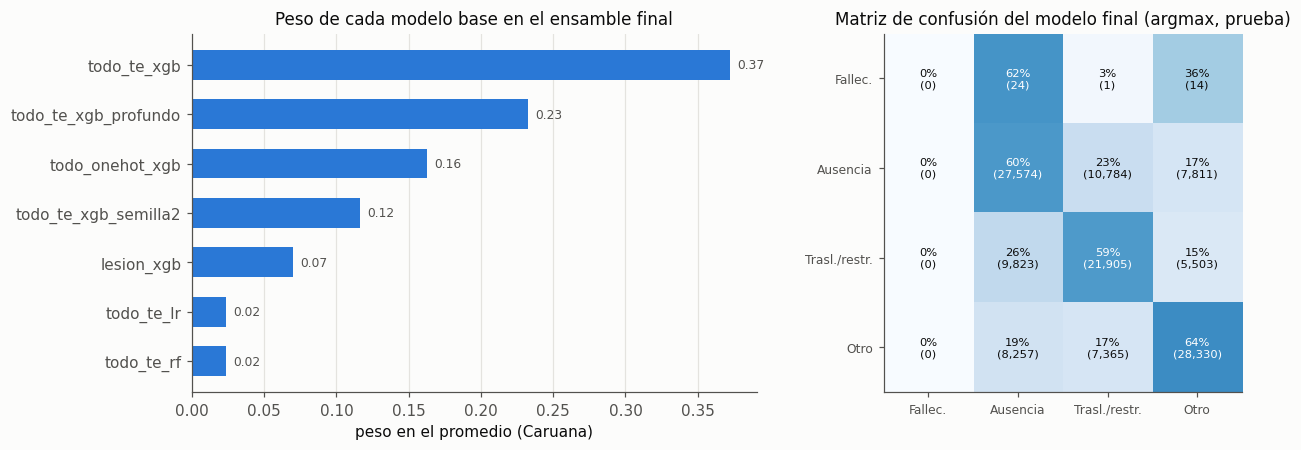

Modelos base sin peso (no los eligió la selección): ['curso_knn', 'curso_logreg', 'curso_naive_bayes', 'curso_random_forest', 'curso_xgboost', 'empleador_te_lr', 'finos_te_xgb', 'lesion_lr', 'todo_onehot_lr']


In [12]:
w = pd.Series(json.loads(str(dfin['weights']))).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1.2, 1]})
axes[0].barh(w.index, w.values, color=P.SERIES[0], height=0.6); axes[0].set_xlabel('peso en el promedio (Caruana)')
axes[0].set_title('Peso de cada modelo base en el ensamble final'); axes[0].grid(axis='y', visible=False)
for i_, v_ in enumerate(w.values):
    axes[0].text(v_ + 0.005, i_, f'{v_:.2f}', va='center', fontsize=8, color=P.INK2)
cm = confusion_matrix(yt, pfin.argmax(1), labels=range(4)); pct = cm / cm.sum(1, keepdims=True) * 100
short = ['Fallec.', 'Ausencia', 'Trasl./restr.', 'Otro']
axes[1].imshow(pct, cmap='Blues', vmin=0, vmax=100)
for i in range(4):
    for j in range(4):
        axes[1].text(j, i, f'{pct[i, j]:.0f}%\n({cm[i, j]:,})', ha='center', va='center', fontsize=7.5, color='white' if pct[i, j] > 55 else P.INK)
axes[1].set_xticks(range(4), short, fontsize=8); axes[1].set_yticks(range(4), short, fontsize=8); axes[1].grid(False)
axes[1].set_title('Matriz de confusión del modelo final (argmax, prueba)')
fig.tight_layout(); P.save(fig, 'e3_propuesto_pesos'); plt.show()
print('Modelos base sin peso (no los eligió la selección):', sorted(set(k[5:] for k in dfin.files if k.startswith('base_')) - set(w.index)))

**Observado.**
- La selección de Caruana usó 7 de los 16 modelos:
  - el XGBoost sobre toda la información (37 %);
  - su versión profunda (23 %);
  - el XGBoost sobre one-hot de lugar y lesión (16 %);
  - el XGBoost con otra semilla (12 %);
  - la vista de la lesión con XGBoost (7 %);
  - Random Forest y logística sobre codificación por objetivo (2 % cada uno).
- Ninguno de los 5 modelos del curso entró.
- En la matriz de confusión, las tres clases frecuentes se reconocen entre el 59 % y el 65 %, frente al
  37 % a 65 % de los mejores modelos del capítulo 9. La mejora más grande es en «días de ausencia», que
  pasa de un 37 % a 41 % a un 60 %.

**Interpretación.** El ensamble se apoya en modelos que ven la misma información con sesgos distintos (poca
y mucha profundidad, codificación por objetivo y one-hot, otra partición de la codificación). Sus errores
están menos correlacionados entre sí que los de los modelos del curso, y promediarlos reduce la varianza
sin aumentar el sesgo, que es la razón clásica por la que unir modelos funciona. Los modelos del curso
no aportan nada que los demás no tengan.

## 18.11 Límites

- **Variables nuevas.** La mejora depende de variables que los capítulos 6 a 13 no usaban. Los códigos de
  la lesión los asigna OSHA a partir del relato **después** del reporte, igual que el SOC, así que el
  modelo es retrospectivo: sirve para clasificar casos reportados, no para alertar antes del incidente.
  Se verificó que ninguna categoría revela el desenlace, pero el relato del que salen sí lo menciona en
  algunos fallecimientos (capítulo 16), y no se puede descartar una fuga indirecta pequeña en esa clase.
- **Vista del empleador.** Usa casos de otros establecimientos de la misma empresa. Es información
  disponible al predecir, pero depende de que la empresa ya tenga casos registrados: el 55 % de los casos
  de prueba pertenece a empresas presentes en el desarrollo. Sin esta vista el ensamble pierde alrededor
  de un punto de accuracy (variante B) y sigue superando al curso.
- **Mismo diseño que los capítulos 6 a 13, no el de Iván.** La comparación usa los 5 pliegues por
  establecimiento y la submuestra de 30.030 casos. No se reevaluó en los 3 pliegues temporales del
  capítulo 17, así que sus cifras no se comparan con las de ese capítulo.
- **Sin búsqueda de hiperparámetros propia.** Los modelos del curso usan los hiperparámetros de la
  validación anidada; los modelos nuevos usan valores fijos razonables. La métrica externa sale de
  pliegues que no participaron en ninguna elección, salvo la elección entre las variantes A a G, que se
  hizo mirando los pliegues y la prueba (efecto de selección: la ventaja de G sobre D puede estar algo
  sobrestimada).
- **Regresión.** El ensamble se construyó para la clasificación; no se aplicó a los días de ausencia.
- **Costo.** Entrenar el modelo final tarda unos 28 minutos (frente a segundos de una logística), por los
  16 modelos y los 6 ajustes de cada uno.